<div align="center">

<!-- Animated Header -->
<img src="https://capsule-render.vercel.app/api?type=waving&height=180&color=0:060B19,50:0E7490,100:22D3EE&text=TIME%20SERIES%20FORECASTING&fontColor=ffffff&fontSize=30&fontAlignY=38&animation=fadeIn&desc=Stock%20Market%20Data%20%7C%20ARIMA%20%7C%20SARIMA%20%7C%20SARIMAX&descSize=15&descAlignY=62" width="100%" alt="Time Series Forecasting Header" />

<!-- Circle Profile Photo -->
<a href="https://github.com/ahsanullahghani000-png">
  <img src="https://wsrv.nl/?url=github.com/ahsanullahghani000-png.png&w=250&h=250&fit=cover&mask=circle" width="130" alt="Ahsanullah Ghani" />
</a>

### Time Series Forecasting of Stock Market data using ARIMA SARIMA Sarimax

**By Ahsanullah Ghani**

<!-- Typing Animation -->
<img src="https://readme-typing-svg.demolab.com?font=JetBrains+Mono&weight=600&size=17&duration=2800&pause=900&color=22D3EE¢er=true&vCenter=true&width=580&lines=Stock+Market+Time+Series+Forecasting;ARIMA+%7C+SARIMA+%7C+SARIMAX+Models;Trend%2C+Seasonality+%26+Exogenous+Features" alt="Typing SVG" />

<br/>

<!-- Project & Role Badges -->
<img src="https://img.shields.io/badge/Project-Time%20Series%20Forecasting-0E7490?style=for-the-badge&logo=plotly&logoColor=white" alt="Project Badge" />
<img src="https://img.shields.io/badge/Models-ARIMA%20%7C%20SARIMA%20%7C%20SARIMAX-060B19?style=for-the-badge&logo=python&logoColor=22D3EE" alt="Models Badge" />
<img src="https://img.shields.io/badge/Domain-Stock%20Market%20Analytics-14B8A6?style=for-the-badge&logo=pandas&logoColor=white" alt="Domain Badge" />

<br/><br/>

<!-- Social Links with Icons -->
<a href="https://www.linkedin.com/in/ahsan-ghani-843434351/">
  <img src="https://img.shields.io/badge/LinkedIn-0A66C2?style=for-the-badge&logo=linkedin&logoColor=white" alt="LinkedIn" />
</a>
<a href="https://github.com/ahsanullahghani000-png">
  <img src="https://img.shields.io/badge/GitHub-060B19?style=for-the-badge&logo=github&logoColor=22D3EE" alt="GitHub" />
</a>
<a href="https://www.instagram.com/ahsanswatiii/">
  <img src="https://img.shields.io/badge/Instagram-E4405F?style=for-the-badge&logo=instagram&logoColor=white" alt="Instagram" />
</a>
<a href="mailto:ahsanullahghani000@gmail.com">
  <img src="https://img.shields.io/badge/Gmail-EA4335?style=for-the-badge&logo=gmail&logoColor=white" alt="Gmail" />
</a>

<br/><br/>

<!-- Animated Footer -->
<img src="https://capsule-render.vercel.app/api?type=waving&height=95&color=0:22D3EE,50:0E7490,100:060B19§ion=footer" width="100%" alt="footer" />

</div>

## 📈 What is a Time Series?

A **time series** is a sequence of observations recorded over time at consistent intervals—such as **daily closing stock prices**, hourly trading volume, or monthly revenue. Unlike cross-sectional data, **time order matters**: current values often depend on past values (**autocorrelation**).

### Key Components
* **Trend ($T_t$):** Long-term direction of the series over time (upward, downward, or flat).
* **Seasonality ($S_t$):** Regular, repeating patterns over fixed cycles (daily, weekly, monthly, or quarterly).
* **Cyclicality ($C_t$):** Multi-year swings driven by broader economic conditions without a fixed period.
* **Residuals / Noise ($R_t$):** Random fluctuations left over after extracting trend and seasonality.

### Why It Matters for ARIMA, SARIMA & SARIMAX
| Model | Best For | Key Capability |
| :--- | :--- | :--- |
| **ARIMA** $(p, d, q)$ | Non-seasonal series with trend | Uses differencing ($d$) to achieve stationarity plus AR ($p$) and MA ($q$) terms |
| **SARIMA** $(p, d, q)(P, D, Q)_s$ | Series with **seasonality** + trend | Adds seasonal autoregressive, differencing, and moving-average terms over period $s$ |
| **SARIMAX** | Seasonal series + **external drivers** | Extends SARIMA with exogenous variables ($X$), such as volume, interest rates, or market indices |

# **Stock Market Data Scraping Using Python**

In [1]:
#import libaries
import pandas as pd,numpy as np ,seaborn as sns,matplotlib.pyplot as plt
import yfinance as yf
import datetime as dt
from datetime import date,timedelta
import plotly.graph_objects as go
import plotly.express as px
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX


In [42]:
# define the dates to fetch data
today = date.today()
d1 = today.strftime("%Y-%m-%d")
end_date = d1
d2 = date.today() - timedelta(days=365)
d2 = d2.strftime("%Y-%m-%d")
start_date = d2
print("Your data will be between these dates: ", start_date, end_date)

# define the ticker
ticker = 'GOOGL'

df = yf.download(ticker, start=start_date, end=end_date, progress=False)
df.head()

Your data will be between these dates:  2025-11-24 2026-11-24


Price,Close,High,Low,Open,Volume
Ticker,GOOGL,GOOGL,GOOGL,GOOGL,GOOGL
Date,,,,,
2025-11-24,317.753601,318.651291,308.796914,310.322944,85165100
2025-11-25,322.601013,327.977016,316.826024,325.363817,88632100
2025-11-26,319.120087,323.658272,315.968280,319.848174,51373400
2025-11-28,319.349487,326.002200,315.968296,322.531215,26018600
2025-12-01,314.073242,319.020368,313.075836,316.875951,41183000


In [43]:
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,GOOGL,GOOGL,GOOGL,GOOGL,GOOGL
count,251.000000,251.000000,251.000000,251.000000,2.510000e+02
mean,333.359853,337.574367,329.189436,333.474921,3.214452e+07
std,29.140364,29.105928,28.529365,28.657488,1.495176e+07
min,265.290009,276.746712,264.220001,274.500000,1.009740e+07
25%,312.342392,314.473244,308.758183,311.688665,2.353865e+07
50%,335.603668,339.399008,331.406986,335.567237,2.857690e+07
75%,349.722992,356.540392,345.914349,350.882216,3.580350e+07
max,402.121185,408.103767,395.868935,399.424550,1.397383e+08


In [44]:

df.columns

MultiIndex([( 'Close', 'GOOGL'),
            (  'High', 'GOOGL'),
            (   'Low', 'GOOGL'),
            (  'Open', 'GOOGL'),
            ('Volume', 'GOOGL')],
           names=['Price', 'Ticker'])

In [45]:
df = df.reset_index()
print(df.head())

Price        Date       Close        High         Low        Open    Volume
Ticker                  GOOGL       GOOGL       GOOGL       GOOGL     GOOGL
0      2025-11-24  317.753601  318.651291  308.796914  310.322944  85165100
1      2025-11-25  322.601013  327.977016  316.826024  325.363817  88632100
2      2025-11-26  319.120087  323.658272  315.968280  319.848174  51373400
3      2025-11-28  319.349487  326.002200  315.968296  322.531215  26018600
4      2025-12-01  314.073242  319.020368  313.075836  316.875951  41183000


In [46]:
import plotly.express as px

# Reset Date index if it's not a column yet, and flatten MultiIndex columns
if "Date" not in df.columns.get_level_values(0):
  df = df.reset_index()

if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.droplevel(1)

# make a plot on plotly
fig = px.line(df, x="Date", y=df.columns, title="Stock Price")
fig.show()

In [47]:
#select the columns
df = df[['Date','Close']]

In [48]:
df.describe()

Price,Date,Close
count,251,251.000000
mean,2026-05-26 11:39:55,333.359853
min,2025-11-24 00:00:00,265.290009
25%,2026-02-25 12:00:00,312.342392
50%,2026-05-27 00:00:00,335.603668
75%,2026-08-25 12:00:00,349.722992
max,2026-11-23 00:00:00,402.121185
std,NaN,29.140364


In [49]:
df.head()

Price,Date,Close
0,2025-11-24,317.753601
1,2025-11-25,322.601013
2,2025-11-26,319.120087
3,2025-11-28,319.349487
4,2025-12-01,314.073242


In [50]:


# Drop the 'Ticker' level so columns become clean strings: 'Date', 'Close', etc.
df_clean = df.copy()
if isinstance(df_clean.columns, pd.MultiIndex):
  df_clean.columns = df_clean.columns.droplevel(1)

# Visualize the data
fig = px.line(
    df_clean,
    x="Date",
    y="Close",
    title=f"{ticker} Stock Price from {start_date} to {end_date}",
)
fig.show()

 # ***Apply the ARIMA Model***
 Check the Asumption Of ARIMA Model
 1. Stationary

In [51]:
#define the function

from statsmodels.tsa.stattools import adfuller
def check_stationarity(df):
    result = adfuller(df)
    print('ADF Statistic: %f' % result[0])
    print('p-value: %f' % result[1])
    if result[1]<=0.05:
        print("The Data Is Stionary")
    else:
        print("The Data Is Not Stionary")
check_stationarity(df['Close'])

ADF Statistic: -1.550961
p-value: 0.508168
The Data Is Not Stionary


C:\Users\AHSAN GHANI\AppData\Local\Temp\ipykernel_12952\3098170065.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df)


**The Data is not a Stationary, Therefore We Can Not Use The ARIMA Model**

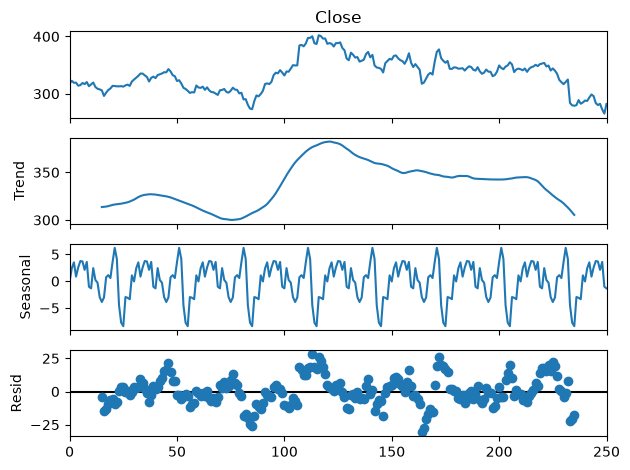

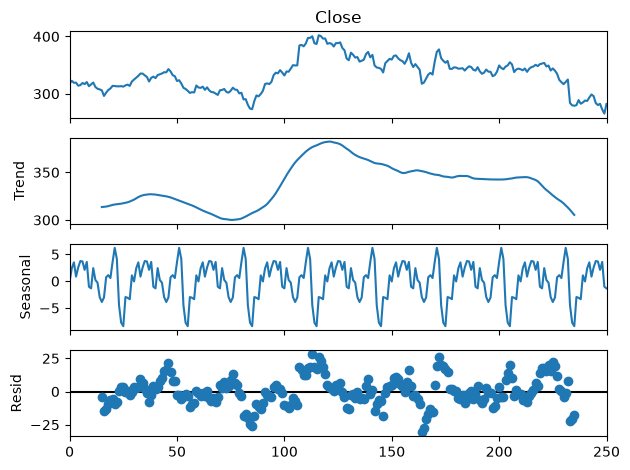

In [52]:
#decompose the data
from statsmodels.tsa.seasonal import seasonal_decompose
decompose = seasonal_decompose(df['Close'],model='additive',period=30)
decompose.plot()

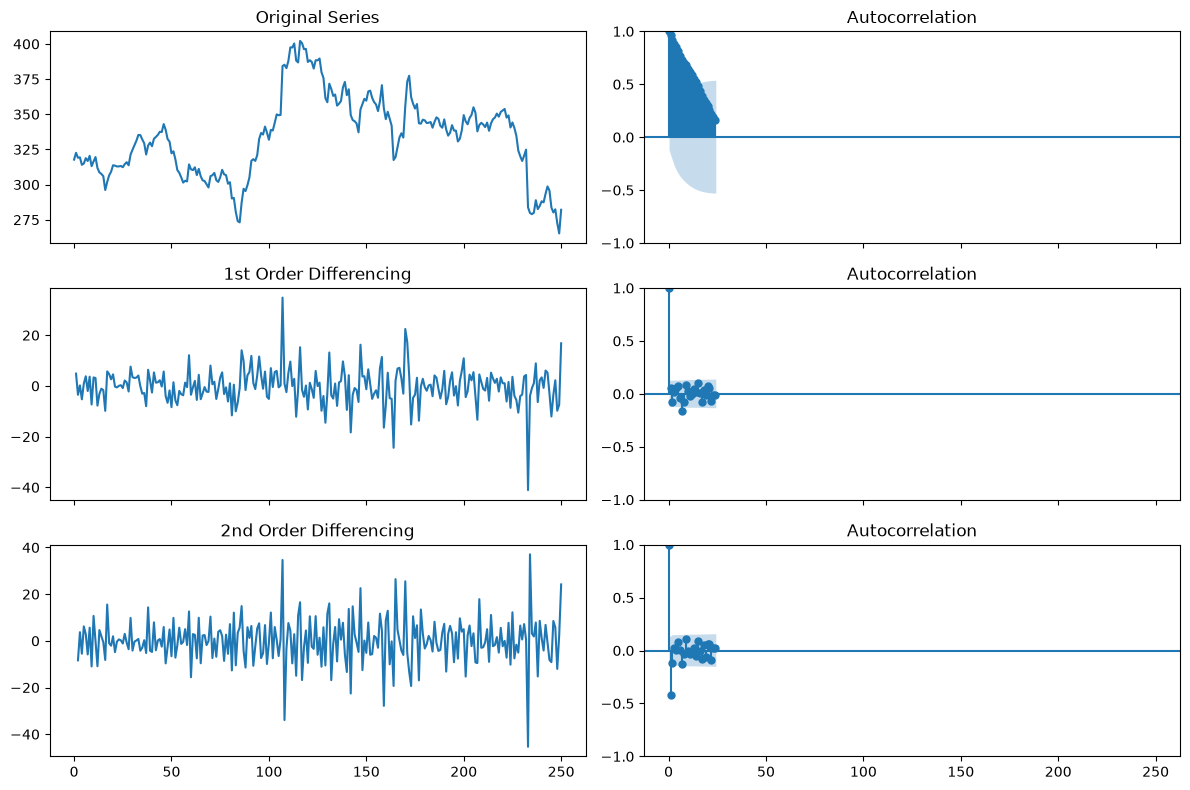

In [53]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Original Series
fig, axes = plt.subplots(3, 2, sharex=True, figsize=(12, 8))
axes[0, 0].plot(df["Close"])
axes[0, 0].set_title("Original Series")
plot_acf(df["Close"].dropna(), ax=axes[0, 1])

# 1st Differencing
axes[1, 0].plot(df["Close"].diff())
axes[1, 0].set_title("1st Order Differencing")
plot_acf(df["Close"].diff().dropna(), ax=axes[1, 1])

# 2nd Differencing
axes[2, 0].plot(df["Close"].diff().diff())
axes[2, 0].set_title("2nd Order Differencing")
plot_acf(df["Close"].diff().diff().dropna(), ax=axes[2, 1])

plt.tight_layout()
plt.show()

 **D** =**1**

# ***let Find the value of P***

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

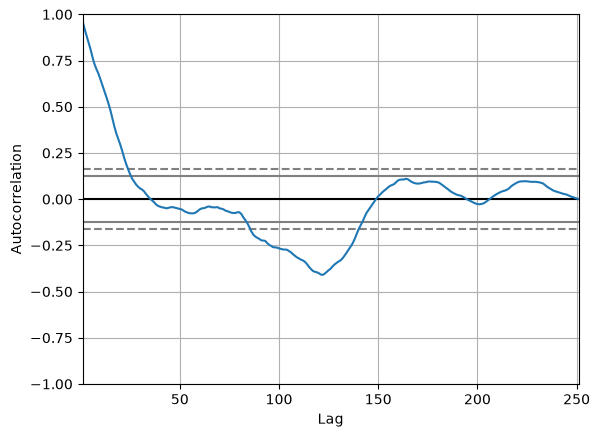

In [54]:
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

pd.plotting.autocorrelation_plot(df["Close"])


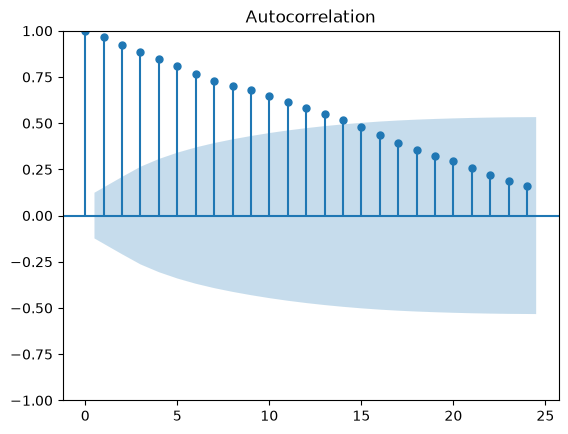

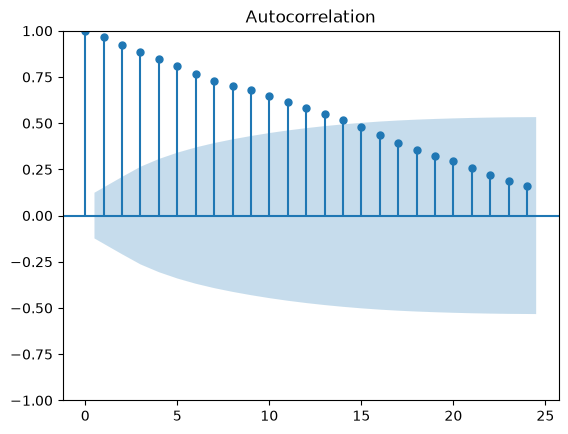

In [55]:
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# pd.plotting.autocorrelation_plot(df["Close"])
plot_acf(df['Close'],alpha=0.05)

In [56]:
import pandas as pd
from statsmodels.tsa.stattools import acf, pacf

x_acf = pd.DataFrame(acf(df["Close"].dropna()))
print(x_acf)


           0
0   1.000000
1   0.964067
2   0.921389
3   0.884913
4   0.849731
5   0.810495
6   0.767570
7   0.729930
8   0.702527
9   0.678536
10  0.647785
11  0.615644
12  0.584141
13  0.551816
14  0.518253
15  0.481202
16  0.437837
17  0.393277
18  0.354807
19  0.324745
20  0.294363
21  0.259153
22  0.221500
23  0.188956


**P** = **2**

# **Let find the q Value**

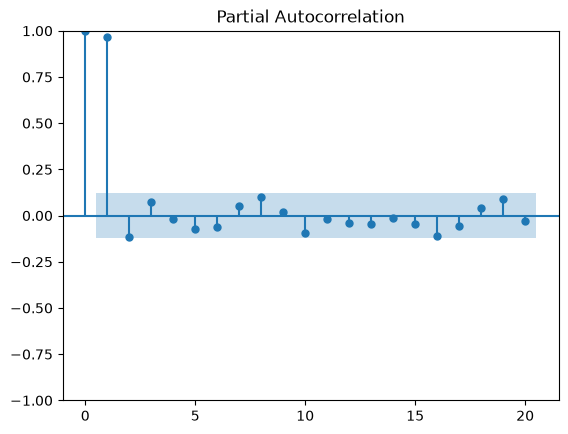

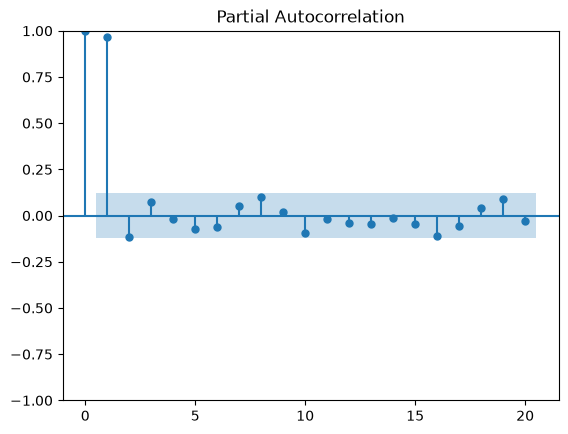

In [57]:
plot_pacf(df['Close'],lags=20,alpha=0.05)

**q** = **2**

# ***Let's Define the (p.q,d) values***
1. p=2
2. d=1
3. q=2

In [58]:
%pip install pmdarima

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
from pmdarima.arima import auto_arima

model = auto_arima(
    df['Close'].dropna(),
    start_p=1,
    start_q=1,
    max_p=2,
    max_q=2,
    m=12,
    start_P=0,
    seasonal=True,
    d=1,
    D=1,
    trace=True,
    error_action='ignore',
    suppress_warnings=True
)
print(model.summary())

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,1,1)[12]             : AIC=inf, Time=1.26 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=1775.185, Time=0.07 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=1707.494, Time=0.38 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=inf, Time=0.93 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=1776.684, Time=0.06 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=1683.689, Time=0.64 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=inf, Time=2.34 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=inf, Time=0.95 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=1683.113, Time=0.43 sec
 ARIMA(0,1,0)(1,1,0)[12]             : AIC=1706.811, Time=0.16 sec
 ARIMA(0,1,0)(2,1,1)[12]             : AIC=inf, Time=1.37 sec
 ARIMA(0,1,0)(1,1,1)[12]             : AIC=inf, Time=0.66 sec
 ARIMA(0,1,1)(2,1,0)[12]             : AIC=1683.602, Time=0.69 sec
 ARIMA(1,1,1)(2,1,0)[12]             : AIC=1685.455, Time=1.23 sec
 ARIMA(0,1,0)(2,1,0)[12] intercept   : AIC=1684.9

In [65]:
from statsmodels.tsa.arima.model import ARIMA

p, d, q = 2, 1, 0

model = ARIMA(df['Close'].dropna(), order=(p, d, q))
model = model.fit()
print(model.summary())




                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                  251
Model:                 ARIMA(2, 1, 0)   Log Likelihood                -841.336
Date:                Tue, 24 Nov 2026   AIC                           1688.672
Time:                        23:55:29   BIC                           1699.236
Sample:                             0   HQIC                          1692.924
                                - 251                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0589      0.079      0.747      0.455      -0.096       0.213
ar.L2         -0.0858      0.074     -1.153      0.249      -0.232       0.060
sigma2        49.0451      2.132     23.000      0.0

251    284.871552
252    286.449813
253    283.571358
254    282.752952
255    285.564105
256    285.701990
257    283.100275
258    283.539450
259    285.824175
260    284.925960
261    283.030973
262    284.264451
263    285.730042
264    284.283154
265    283.256763
266    284.803454
267    285.406363
268    283.860384
269    283.644740
270    285.105919
271    284.985704
272    283.675081
273    284.069839
274    285.183073
275    284.580042
276    283.692642
277    284.437139
278    285.087199
279    284.264854
280    283.848838
281    284.691546
Name: predicted_mean, dtype: float64


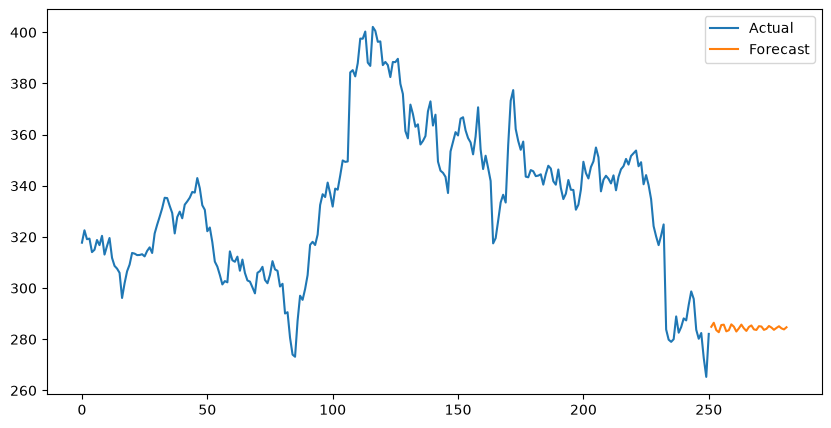

In [61]:
import matplotlib.pyplot as plt

forecast = model.predict(len(df["Close"]), len(df["Close"]) + 30)
print(forecast)

plt.figure(figsize=(10, 5))
plt.plot(df["Close"], label="Actual")
plt.plot(forecast, label="Forecast")
plt.legend()
plt.show()

 The ARIMA Model are apply thr data but cannot give the accurate result therefore we apply the SARIMA Model because The Seasonality are present in this dataset

# **Apply The SARIMA Model**

In [66]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

p, d, q = 2, 1, 0

model = sm.tsa.statespace.SARIMAX(
    df['Close'].dropna(), order=(p, d, q), seasonal_order=(p, d, q, 12)
)
fitted_model = model.fit()



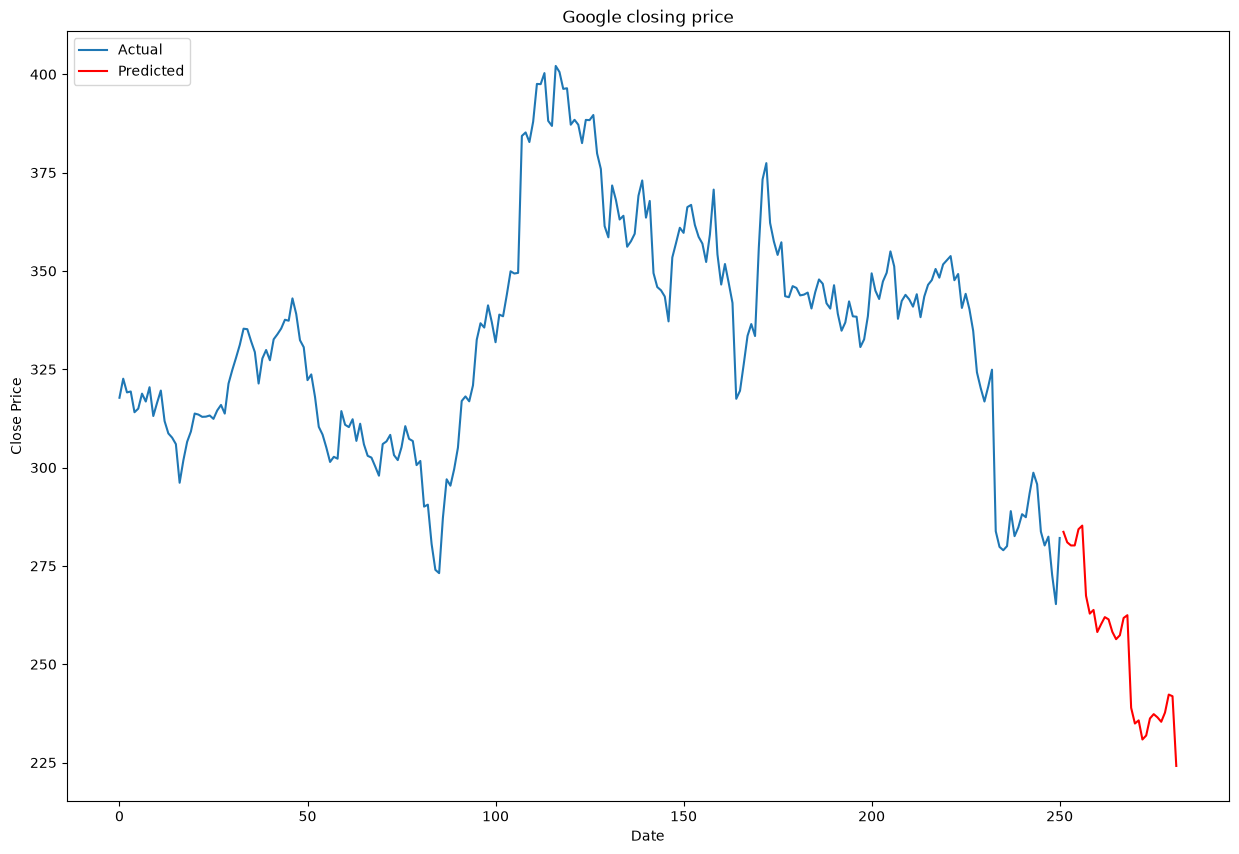

In [67]:
predictions = fitted_model.predict(
    start=len(df['Close']), end=len(df['Close']) + 30
)

plt.figure(figsize=(15, 10))
plt.plot(df['Close'], label='Actual')
plt.plot(predictions, color='red', label='Predicted')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.title('Google closing price')
plt.legend(loc='upper left')
plt.show()